# Uncertainty with Bayesian DJINN

With dropout left on at prediction time, each pass through a network gives a
slightly different answer. Running many passes through every network in the
ensemble gives a spread of predictions for each input, which can be used as an
estimate of the model's uncertainty.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

from djinn import DJINN_Regressor

In [2]:
X, y = fetch_california_housing(return_X_y=True)
rng = np.random.default_rng(0)
idx = rng.choice(len(y), 3000, replace=False)
X_train, X_test, y_train, y_test = train_test_split(
    X[idx], y[idx], test_size=0.2, random_state=0
)
X_fit, X_cal, y_fit, y_cal = train_test_split(
    X_train, y_train, test_size=0.25, random_state=0
)
X_fit.shape, X_cal.shape, X_test.shape

((1800, 8), (600, 8), (600, 8))

A quarter of the training data is held back as a calibration set. The model
never sees it during training. It's only used at the end, to build intervals
with a known coverage.

## Fit with dropout

`dropout_keep_prob` is the chance that a hidden neuron is kept in each pass.
Values around 0.95 with 5 to 10 trees work well. Dropout is applied during
training too, so the networks learn to cope with it.

In [3]:
%%time
model = DJINN_Regressor(
    n_trees=5,
    max_tree_depth=6,
    dropout_keep_prob=0.95,
    learning_rate=0.005,
    epochs=300,
    random_state=0,
)
model.fit(X_fit, y_fit)

CPU times: user 10min 29s, sys: 546 ms, total: 10min 29s
Wall time: 53.3 s


,n_trees,5
,max_tree_depth,6
,dropout_keep_prob,0.95
,epochs,300
,learning_rate,0.005
,batch_size,None
,weight_decay,1e-08
,random_state,0
,device,'cpu'
,verbose,0


## Sampling predictions

`bma_predict()` runs `n_iters` passes through each network with dropout on.
It returns the 25th, 50th and 75th percentiles of the predictions, and all the
samples with shape `(n_iters * n_trees, n_test, n_outputs)`.

In [4]:
result = model.bma_predict(X_test, n_iters=50, seed=0)
lower = result["lower"].ravel()
middle = result["middle"].ravel()
upper = result["upper"].ravel()
samples = result["predictions"][:, :, 0]
samples.shape

(250, 600)

In [5]:
r2 = 1 - np.sum((y_test - middle) ** 2) / np.sum((y_test - y_test.mean()) ** 2)
print(f"R2 of the median prediction: {r2:.3f}")

R2 of the median prediction: 0.695


The plot shows 80 test points sorted by their median prediction. The bars are
the 25th to 75th percentile and the dots are the true values.

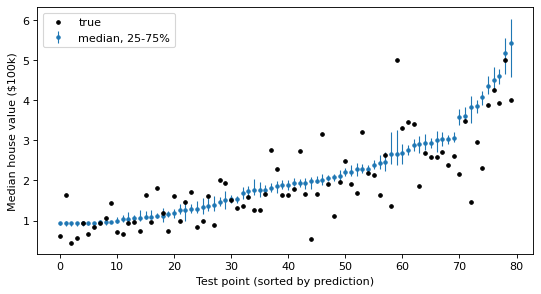

In [6]:
pick = np.sort(np.random.default_rng(1).choice(len(y_test), 80, replace=False))
order = pick[np.argsort(middle[pick])]
x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(8, 4), dpi=80)
ax.errorbar(
    x,
    middle[order],
    yerr=[middle[order] - lower[order], upper[order] - middle[order]],
    fmt="o",
    ms=3,
    lw=1,
    label="median, 25-75%",
)
ax.scatter(x, y_test[order], s=10, color="k", zorder=3, label="true")
ax.set_xlabel("Test point (sorted by prediction)")
ax.set_ylabel("Median house value ($100k)")
ax.legend()
plt.show()

## How well do the intervals cover?

If the spread were a calibrated predictive distribution, about 50% of the true
values would land inside the 25-75% interval and about 90% inside the 5-95%
interval. Checking this on held-out data is the simplest test of whether the
intervals can be taken at face value.

In [7]:
p5, p95 = np.percentile(samples, [5, 95], axis=0)
inside_50 = np.mean((y_test >= lower) & (y_test <= upper))
inside_90 = np.mean((y_test >= p5) & (y_test <= p95))
print(f"Inside 25-75%: {inside_50:.0%} (50% if calibrated)")
print(f"Inside 5-95%:  {inside_90:.0%} (90% if calibrated)")

Inside 25-75%: 20% (50% if calibrated)
Inside 5-95%:  51% (90% if calibrated)


MC dropout only captures part of the uncertainty. It reflects how unsure the
networks are about their own weights, not the noise in the targets, so the
intervals come out too narrow. Lowering `dropout_keep_prob` widens them, but on
most data not by enough, and the model gets less accurate.

## Calibrated intervals

`calibrate()` records how far `predict()` is from the true values on the
calibration set. `predict_interval()` then gives the prediction plus or minus
the error that the requested share of those points fall within. As long as the
test data comes from the same place as the calibration data, the coverage
holds.

In [8]:
model.calibrate(X_cal, y_cal)

for coverage in [0.5, 0.9]:
    lo, hi = model.predict_interval(X_test, coverage=coverage)
    inside = np.mean((y_test >= lo) & (y_test <= hi))
    print(f"coverage={coverage}: {inside:.0%} inside, width {np.mean(hi - lo):.2f}")

coverage=0.5: 51% inside, width 0.68
coverage=0.9: 89% inside, width 1.80


The same 80 points with the 90% calibrated interval. Every point gets the same
width, since the dropout spread turned out to say little about which
predictions are off by the most.

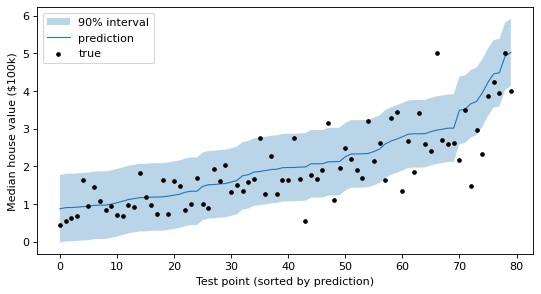

In [9]:
lo90, hi90 = model.predict_interval(X_test, coverage=0.9)
pred = model.predict(X_test)
order = pick[np.argsort(pred[pick])]

fig, ax = plt.subplots(figsize=(8, 4), dpi=80)
ax.fill_between(x, lo90[order], hi90[order], alpha=0.3, label="90% interval")
ax.plot(x, pred[order], lw=1, label="prediction")
ax.scatter(x, y_test[order], s=10, color="k", zorder=3, label="true")
ax.set_xlabel("Test point (sorted by prediction)")
ax.set_ylabel("Median house value ($100k)")
ax.legend()
plt.show()

## How many passes?

More passes give smoother percentiles but take longer. The interval widths
settle down after a few dozen passes per network.

In [10]:
for n_iters in [5, 20, 50, 100]:
    r = model.bma_predict(X_test, n_iters=n_iters, seed=0)
    width = np.mean(r["upper"] - r["lower"])
    print(f"n_iters={n_iters:<4} mean 25-75% width={width:.3f}")

n_iters=5    mean 25-75% width=0.298
n_iters=20   mean 25-75% width=0.306


n_iters=50   mean 25-75% width=0.309


n_iters=100  mean 25-75% width=0.306
